# JavierGarciaVillarraso_Practica2


In [20]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import accuracy_score, confusion_matrix
print("Versión de TensorFlow:", tf.__version__)

# Definir una semilla fija para la reproducibilidad de los resultados
SEED = 67

# Fijar semilla
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

Versión de TensorFlow: 2.20.0


## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

Cargamos los datos:

In [21]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [22]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento

In [23]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

# Clasificación a Par (0) / Impar (1)
y_train_bin = (y_train % 2).astype(np.float32)
y_test_bin = (y_test % 2).astype(np.float32)

## Modelo 1 (Mejor modelo de la práctica 1 con las modificaciones justas para clasificar pares e impares)

In [24]:
# Capa de salida con 1 neurona y activación 'sigmoid'
model1 = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(28, 28)),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compilador con binary_crossentropy
model1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento usando y_train_bin
t0 = time.time()
h1 = model1.fit(x_train, y_train_bin, epochs=5, batch_size=32)
time1 = time.time() - t0

# Predicciones
pred_train1 = (model1.predict(x_train, verbose=0) >= 0.5).astype(int).flatten()
pred_test1 = (model1.predict(x_test, verbose=0) >= 0.5).astype(int).flatten()

# Evaluar con las etiquetas binarias (y_train_bin e y_test_bin)
acc_tr1 = accuracy_score(y_train_bin, pred_train1)
acc_te1 = accuracy_score(y_test_bin, pred_test1)
err_tr1 = np.sum(y_train_bin != pred_train1)
err_te1 = np.sum(y_test_bin != pred_test1)

cm_train1 = confusion_matrix(y_train_bin, pred_train1)
cm_test1 = confusion_matrix(y_test_bin, pred_test1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9577 - loss: 0.1160
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9811 - loss: 0.0562
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9869 - loss: 0.0398
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9903 - loss: 0.0293
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9932 - loss: 0.0218


# Modelo 2 (probando con más capas y Dropout)


In [25]:
# Definición del Modelo 2 con arquitectura modificada
model2 = tf.keras.models.Sequential([
  tf.keras.layers.Input(shape=(28, 28)),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),                   # Capa Dropout añadida
  tf.keras.layers.Dense(64, activation='relu'),    # Capa Dense adicional
  tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compilación
model2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento
t0 = time.time()
h2 = model2.fit(x_train, y_train_bin, epochs=5, batch_size=32)
time2 = time.time() - t0

# Predicciones
pred_train2 = (model2.predict(x_train, verbose=0) >= 0.5).astype(int).flatten()
pred_test2 = (model2.predict(x_test, verbose=0) >= 0.5).astype(int).flatten()

# Métricas
acc_tr2 = accuracy_score(y_train_bin, pred_train2)
acc_te2 = accuracy_score(y_test_bin, pred_test2)
err_tr2 = np.sum(y_train_bin != pred_train2)
err_te2 = np.sum(y_test_bin != pred_test2)

cm_train2 = confusion_matrix(y_train_bin, pred_train2)
cm_test2 = confusion_matrix(y_test_bin, pred_test2)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9580 - loss: 0.1151
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9785 - loss: 0.0615
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9828 - loss: 0.0498
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9854 - loss: 0.0415
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9880 - loss: 0.0342


# Visualización de Resultados y Conclusiones

,Experimento,Tiempo (s),Acc Train,Acc Test,Errores Test
0,1: Mejor de la práctica 1 (Dense 128),45.24,99.30%,98.53%,147 / 10000
1,2: Modificado (Dense 128 + Dropout 0.2 + Dense...,46.83,99.33%,98.68%,132 / 10000


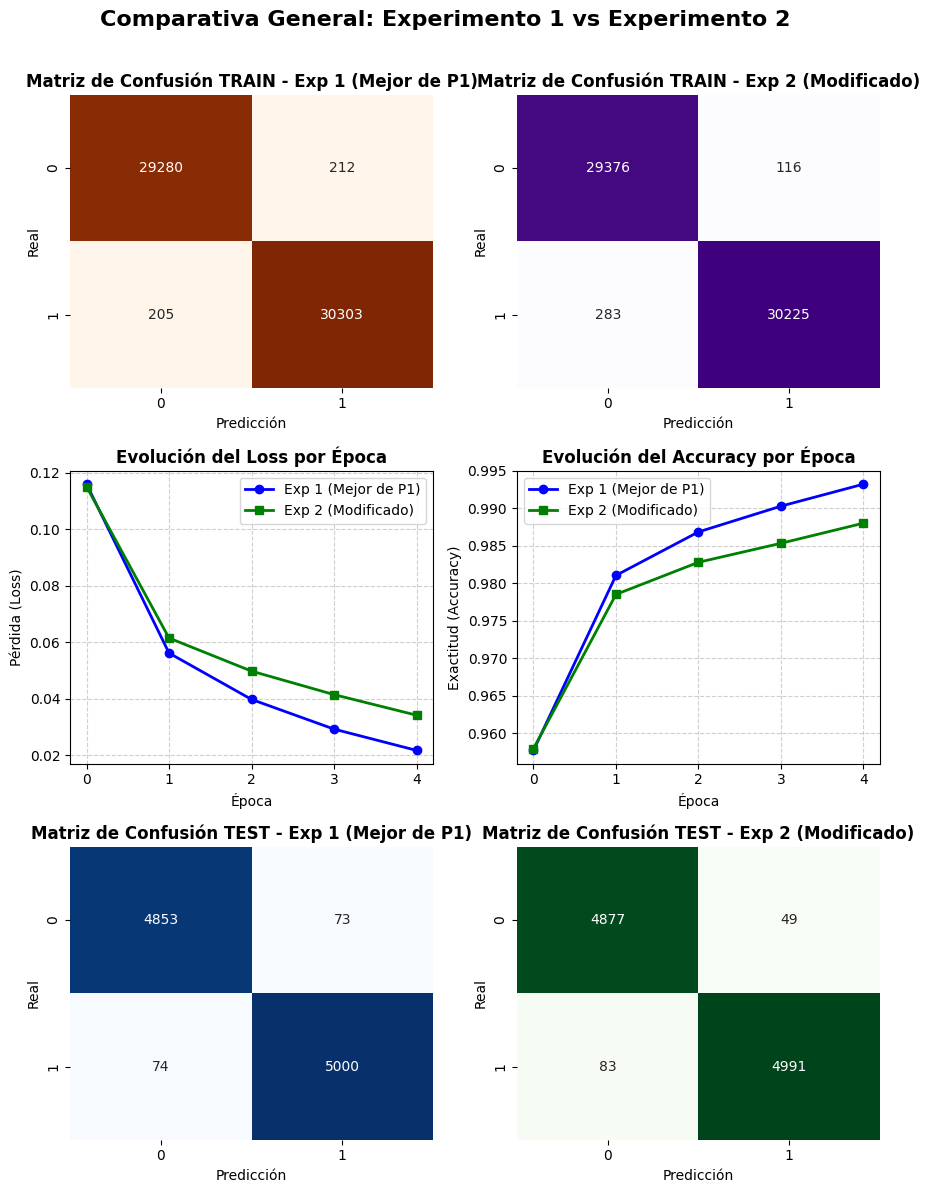

In [26]:
# Tabla resumen comparativa entre Experimento 1 y Experimento 2
resumen_comparativo = pd.DataFrame({
    'Experimento': [
        '1: Mejor de la práctica 1 (Dense 128)',
        '2: Modificado (Dense 128 + Dropout 0.2 + Dense 64)'
    ],
    'Tiempo (s)': [round(time1, 2), round(time2, 2)],
    'Acc Train': [f"{acc_tr1*100:.2f}%", f"{acc_tr2*100:.2f}%"],
    'Acc Test': [f"{acc_te1*100:.2f}%", f"{acc_te2*100:.2f}%"],
    'Errores Test': [f"{err_te1} / 10000", f"{err_te2} / 10000"]
})
display(resumen_comparativo)

# Identificar las claves de accuracy en el historial de Keras
acc_key1 = 'accuracy' if 'accuracy' in h1.history else 'acc'
acc_key2 = 'accuracy' if 'accuracy' in h2.history else 'acc'

# Visualización gráfica en rejilla 3x2 (Fila 1: Train CM, Fila 2: Curvas, Fila 3: Test CM)
fig, axes = plt.subplots(3, 2, figsize=(9, 12))

# -------------------------------------------------------------
# FILA 1: MATRICES DE CONFUSIÓN (TRAIN)
# -------------------------------------------------------------

# (Fila 1, Izquierda) Matriz de Confusión TRAIN - Experimento 1
sns.heatmap(cm_train1, annot=True, fmt='d', cmap='Oranges', ax=axes[0, 0], cbar=False)
axes[0, 0].set_title("Matriz de Confusión TRAIN - Exp 1 (Mejor de P1)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Predicción")
axes[0, 0].set_ylabel("Real")

# (Fila 1, Derecha) Matriz de Confusión TRAIN - Experimento 2
sns.heatmap(cm_train2, annot=True, fmt='d', cmap='Purples', ax=axes[0, 1], cbar=False)
axes[0, 1].set_title("Matriz de Confusión TRAIN - Exp 2 (Modificado)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Predicción")
axes[0, 1].set_ylabel("Real")

# -------------------------------------------------------------
# FILA 2 (ANTES FILA 3): GRÁFICAS COMPARATIVAS CON LÍNEA PARA CADA MODELO
# -------------------------------------------------------------

# (Fila 2, Izquierda) Evolución del Loss
axes[1, 0].plot(h1.history['loss'], label='Exp 1 (Mejor de P1)', color='blue', linewidth=2, marker='o')
axes[1, 0].plot(h2.history['loss'], label='Exp 2 (Modificado)', color='green', linewidth=2, marker='s')
axes[1, 0].set_title('Evolución del Loss por Época', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Época')
axes[1, 0].set_ylabel('Pérdida (Loss)')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# (Fila 2, Derecha) Evolución del Accuracy
axes[1, 1].plot(h1.history[acc_key1], label='Exp 1 (Mejor de P1)', color='blue', linewidth=2, marker='o')
axes[1, 1].plot(h2.history[acc_key2], label='Exp 2 (Modificado)', color='green', linewidth=2, marker='s')
axes[1, 1].set_title('Evolución del Accuracy por Época', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Época')
axes[1, 1].set_ylabel('Exactitud (Accuracy)')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

# -------------------------------------------------------------
# FILA 3: MATRICES DE CONFUSIÓN (TEST)
# -------------------------------------------------------------

# (Fila 3, Izquierda) Matriz de Confusión TEST - Experimento 1
sns.heatmap(cm_test1, annot=True, fmt='d', cmap='Blues', ax=axes[2, 0], cbar=False)
axes[2, 0].set_title("Matriz de Confusión TEST - Exp 1 (Mejor de P1)", fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel("Predicción")
axes[2, 0].set_ylabel("Real")

# (Fila 3, Derecha) Matriz de Confusión TEST - Experimento 2
sns.heatmap(cm_test2, annot=True, fmt='d', cmap='Greens', ax=axes[2, 1], cbar=False)
axes[2, 1].set_title("Matriz de Confusión TEST - Exp 2 (Modificado)", fontsize=12, fontweight='bold')
axes[2, 1].set_xlabel("Predicción")
axes[2, 1].set_ylabel("Real")

# Ajuste general del lienzo
plt.suptitle("Comparativa General: Experimento 1 vs Experimento 2", fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Podemos comprobar observando las gráficas, que durante el entrenamiento, el experimento 1 logra valores más altos en accuracy y más bajos en loss, sin embargo a la hora de generalizar, el nuevo experimento con Dropout y más capas, tiene mejores resultados en test, por tanto, observamos que el drop out ha logrado reducir el sobreajuste del modelo 1.

# Guardamos el modelo en disco

In [27]:
model2.save("JavierGarciaVillarraso_ModeloParImpar.keras")
print("Modelo guardado correctamente.")

Modelo guardado correctamente.


# Mostramos algunos ejemplos clasificados (solamente para visualizar)

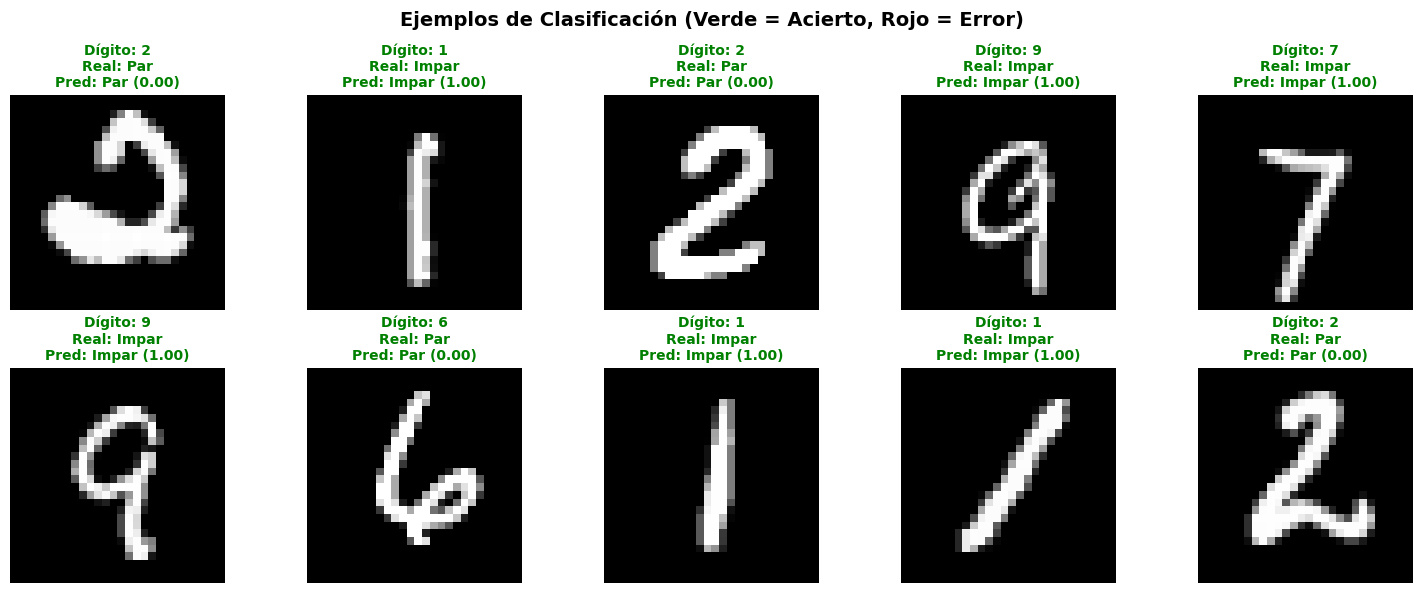

In [28]:
# Seleccionamos 10 índices aleatorios del conjunto de test
np.random.seed(SEED)
indices_muestra = np.random.choice(len(x_test), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, idx in enumerate(indices_muestra):
    imagen = x_test[idx]
    num_real = y_test[idx]  # Número real (0-9)
    clase_real = int(y_test_bin[idx])  # 0: Par, 1: Impar

    # Obtenemos probabilidad y clase predicha
    prob = model2.predict(np.expand_dims(imagen, axis=0), verbose=0)[0][0]
    clase_predicha = int(prob >= 0.5)

    # Mapeo de nombres
    etiquetas = {0: "Par", 1: "Impar"}

    # Color del título: Verde si acertó, Rojo si falló
    correcto = (clase_real == clase_predicha)
    color = 'green' if correcto else 'red'

    # Dibujamos la imagen
    axes[i].imshow(imagen, cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(
        f"Dígito: {num_real}\nReal: {etiquetas[clase_real]}\nPred: {etiquetas[clase_predicha]} ({prob:.2f})",
        color=color,
        fontsize=10,
        fontweight='bold'
    )

plt.suptitle("Ejemplos de Clasificación (Verde = Acierto, Rojo = Error)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()